# LangChain 멀티모달 RAG 실습 — FashionRAG
### CLIP 이미지 검색 + GPT 비전 모델로 만드는 패션 스타일링 어시스턴트

| 항목 | 내용 |
|---|---|
| 준비물 | OpenAI API 키, 디스크 여유 약 3GB, 인터넷 연결 |
| 결과물 | 한국어로 질문하면 비슷한 패션 사진을 찾아 보여주고 스타일링 조언을 해주는 챗봇 |

**사용법**: 위에서부터 셀을 하나씩 `Shift + Enter` 로 실행하세요. 코드의 주석(`#`)을 꼭 읽으면서 진행하세요.
`✏️ 실습` 셀의 `TODO` 부분은 직접 채워 넣는 문제입니다.


## 학습 목표

1. **멀티모달 RAG** 의 구조(Retrieval → Augmentation → Generation)를 설명할 수 있다.
2. **CLIP** 이 텍스트와 이미지를 같은 벡터 공간에 놓는 원리를 이해하고, 텍스트로 이미지를 검색할 수 있다.
3. **Chroma 벡터 DB** 에 이미지를 저장(`add`)하고 검색(`query`)할 수 있다.
4. **LangChain LCEL**(`프롬프트 | 모델 | 파서`)로 번역 체인과 비전 체인을 만들 수 있다.
5. 이미지를 **base64 data URL** 로 변환해 GPT 비전 모델에 전달할 수 있다.

RAG 정의
LLM은 학습하지 않은 정보를 모른다. 그래서 질문과 관련된 자료를 먼저 찾아서(Retrieval), 프롬프트에 붙여넣고(Augmentation) 그 자료를 근거로 답하게(Generation)하는 방식

멀티모답 RAG
모달리티(modality)란 데이터의 종류(텍스트, 이미지, 음성, 영상....)란 뜻이다.
일반 RAG가 텍스트 문서를 검색한다면, 멀티모달RAG는 이미지를 검색하고 이미지를 볼 수 있는 LLM(비전모델)에게 전달하여 답하게 하는 방식

## 목차

| 파트 | 내용 | 셀 |
|---|---|---|
| 0 | 전체 그림: 멀티모달 RAG 란? | 개념 |
| 1 | 환경 준비 (설치·임포트·API 키·설정값) | [환경]~[4] |
| 2 | 데이터 준비: Fashionpedia 스트리밍 | [5]~[7] |
| 3 | 임베딩 & 벡터 DB: CLIP + Chroma | [8]~[11] |
| 4 | LangChain 체인: 번역 체인 / 비전 체인 | [12]~[13] |
| 5 | 전체 파이프라인 & 대화형 모드 | [14]~[16] |
| 6 | 실습 문제 · 퀴즈 · 정리 | 실습 1~4 |


---
# Part 0. 전체 그림: 멀티모달 RAG

### RAG(Retrieval-Augmented Generation) 복습
LLM 은 학습하지 않은 정보(우리 회사 상품, 최신 데이터 등)를 모릅니다. 그래서 **질문과 관련된 자료를 먼저 찾아서(Retrieval)**, **프롬프트에 붙여 넣고(Augmentation)**, **그 자료를 근거로 답하게(Generation)** 하는 방식이 RAG 입니다.

### 멀티모달(Multimodal) RAG
'모달리티(modality)'는 데이터의 종류(텍스트, 이미지, 음성 …)를 뜻합니다.
일반 RAG 가 **텍스트 문서**를 검색한다면, 멀티모달 RAG 는 **이미지**를 검색하고 **이미지를 볼 수 있는 LLM(비전 모델)** 에게 전달합니다.

### 오늘 만들 FashionRAG 의 흐름

```
 사용자(한국어)  "가을 트렌치코트 스타일링 알려줘"
        │
        ▼  ① 번역 체인 (gpt-4o-mini)           ← LangChain LCEL
 "Trench coat styling for autumn"
        │
        ▼  ② CLIP 텍스트 임베딩 → Chroma 유사도 검색   ← Retrieval
 [image_0123.jpg, image_0456.jpg]   (가장 비슷한 사진 2장)
        │
        ▼  ③ 이미지 → base64 data URL, 질문과 함께 프롬프트 구성  ← Augmentation
        │
        ▼  ④ 비전 체인 (gpt-4o-mini, 이미지 이해)            ← Generation
 "In the first image, the beige trench coat ..."
        │
        ▼  ⑤ 번역 체인
 사용자에게 한국어 답변 + 검색된 사진 출력
```

### 사전 준비 단계 (최초 1회)
```
 Fashionpedia 데이터셋 ──(500장 저장)──▶ fashion_dataset/ 폴더
                                          │  CLIP 이미지 임베딩
                                          ▼
                                   Chroma 벡터 DB (img_vdb/)
```


---
# Part 1. 환경 준비

### 핵심 라이브러리 한눈에 보기
| 라이브러리 | 역할 | 오늘 사용하는 기능 |
|---|---|---|
| **datasets** | Hugging Face 데이터셋 로드 | `load_dataset(..., streaming=True)` |
| **open_clip / torch** | CLIP 모델 실행 | Chroma 의 `OpenCLIPEmbeddingFunction` 내부에서 사용 |
| **chromadb** | 벡터 DB | `PersistentClient`, `add`, `query` |
| **langchain-core** | LLM 앱 구성요소 | `ChatPromptTemplate`, `StrOutputParser`, `|` |
| **langchain-openai** | OpenAI 연결 | `ChatOpenAI` |


In [1]:
# ============================================================
# [환경 준비] 필수 패키지 설치  (최초 1회만 실행)
# ============================================================
# %pip  : '지금 이 노트북 커널'의 파이썬 환경에 패키지를 설치하는 매직 명령어
#         (!pip 는 다른 파이썬 환경에 설치될 수 있으므로 %pip 를 권장)
# -q    : 설치 로그를 간단히(quiet) 출력
#
# 패키지별 역할
#   chromadb         : 벡터 데이터베이스 (이미지 임베딩 저장/검색)
#   open-clip-torch  : CLIP 모델 (텍스트·이미지를 같은 벡터 공간으로 임베딩)
#                      -> PyTorch(torch)가 함께 설치되어 수 분 걸릴 수 있음
#   pillow           : 이미지 열기/저장 (PIL)
#   datasets         : Hugging Face 데이터셋 다운로드
#   langchain-core   : 프롬프트 템플릿, 출력 파서, LCEL 체인(|) 등 핵심 기능
#   langchain-openai : LangChain 에서 OpenAI 모델(ChatOpenAI) 사용
#   python-dotenv    : .env 파일의 환경변수(API 키) 로드
#
# 설치 후 "Restart Kernel"이 필요하다는 메시지가 나오면 커널을 재시작한 뒤
# 이 셀은 건너뛰고 다음 셀부터 실행하세요.
install_packages = [
    "chromadb",
    "open-clip-torch",
    "pillow",
    "datasets",
    "langchain-core",
    "langchain-openai",
    "python-dotenv",
] 
print("설치 중... (약 1~2분 소요)")

%pip install -q "chromadb==1.5.9" "langchain-openai==1.6.7" open-clip-torch pillow datasets langchain-core python-dotenv

print("설치 완료! (커널 재시작 필요 시, 'Restart Kernel' 버튼 클릭 후 다음 셀부터 실행)")

설치 중... (약 1~2분 소요)
Note: you may need to restart the kernel to use updated packages.
설치 완료! (커널 재시작 필요 시, 'Restart Kernel' 버튼 클릭 후 다음 셀부터 실행)



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# ============================================================
# [1] 라이브러리 임포트
# ============================================================

# --- 파이썬 표준 라이브러리 ---
import os
import base64
import mimetypes
from getpass import getpass
from pathlib import Path
from typing import List

# .env 파일에서 환경변수 로드
from dotenv import load_dotenv

# 이미지(바이너리) -> 텍스트(base64 문자열) 변환
def image_to_base64(image_path: str | Path) -> str:
    with open(image_path, "rb") as f:
        return base64.b64encode(f.read()).decode("utf-8")

# .env 파일의 환경변수를 미리 불러옵니다.
# API 키가 없으면 다음 셀에서 안전하게 입력받습니다.
load_dotenv()

# --- 벡터 데이터베이스 (Chroma) ---
import chromadb
from chromadb.utils.embedding_functions import OpenCLIPEmbeddingFunction

# OpenCLIPEmbeddingFunction : 텍스트/이미지를 CLIP 벡터로 바꿔주는 임베딩 함수
from chromadb.utils.data_loaders import ImageLoader

# --- 데이터셋 ---
from datasets import load_dataset

# --- LangChain ---
#OpenAI 모델(ChatOpenAI)
from langchain_openai import ChatOpenAI
# 프롬프트 템플릿
from langchain_core.prompts import ChatPromptTemplate
# 모델 응답->순수 문자열
from langchain_core.output_parsers import StrOutputParser

# --- 이미지 처리 & 노트북 출력 ---
#이미지 열기/리사이즈/합치기
from PIL import Image
# 노트북에 이미지 마크다운 예쁘게 출력
from IPython.display import display, Markdown

print("라이브러리 임포트 완료")

라이브러리 임포트 완료


In [5]:
# ============================================================
# [2] OpenAI API 키 설정
# ============================================================
# 

load_dotenv()                                   # .env 파일을 찾아 환경변수로 등록
OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")    # 환경변수에서 키 읽기 (없으면 None)

if not OPENAI_API_KEY:
    # .env 도 환경변수도 없으면 직접 입력받음 (입력 내용은 화면에 표시되지 않음)
    OPENAI_API_KEY = getpass("OpenAI API 키를 입력하세요 (sk-...): ").strip()

if not OPENAI_API_KEY:
    # 그래도 비어 있으면 더 진행할 수 없으므로 명확한 에러를 발생시킴
    raise ValueError("OPENAI_API_KEY 가 설정되지 않았습니다. .env 파일 또는 입력으로 설정하세요.")

# ChatOpenAI 는 환경변수 OPENAI_API_KEY 를 자동으로 읽어 사용함
os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY

# 키 전체를 출력하면 보안상 위험하므로 앞 6자리만 확인용으로 출력
print("API 키 설정 완료:", OPENAI_API_KEY[:6] + "...")

API 키 설정 완료: sk-pro...


### 설정값을 한 곳에 모으는 이유
경로·모델명·개수 같은 값이 코드 곳곳에 흩어져 있으면 바꾸기 어렵습니다. **맨 위 설정 셀만 고치면** 전체 동작이 바뀌도록 만드는 것이 좋습니다.


In [3]:
# ============================================================
# [3] 실습 설정값 (한 곳에서 관리)
# ============================================================
# 원본 스크립트의 os.path.abspath(__file__) 는 .py 파일에서만 동작합니다.
# 주피터 노트북에는 __file__ 변수가 없으므로(NameError) 현재 작업 폴더를 기준으로 합니다.
BASE_DIR = os.getcwd()  # 현재 작업 폴더 (현재 노트북이 있는 폴더)

# 이미지를 저장할 폴더
DATASET_FOLDER  = os.path.join(BASE_DIR, "fashion_dataset")

# Chroma DB 저장 폴더
VDB_PATH        = os.path.join(BASE_DIR, "img_vdb")

# Chroma 컬렉션(=테이블) 이름 (3자 이상, 영문/숫자/._-)
COLLECTION_NAME = "fashion_images"

NUM_IMAGES =500    # 데이터셋에서 가져올 이미지 수 (수업 시간이 부족하면 100 정도로 줄이세요)
N_RESULTS  =2    # 질문 하나당 검색할 이미지 수 (비전 프롬프트에 이미지 2장이 들어감)

# 사용할 OpenAI 모델 이름 
TRANSLATION_MODEL = "gpt-4o-mini"  # 한->영 번역용 
VISION_MODEL      = "gpt-4o-mini"  # 이미지를 이해하는 비전 모델 

# 이미지로 인식할 확장자 (원본은 .png 만 처리) 
IMAGE_EXTS = (".jpg", ".jpeg", ".png")

print("작업 폴더   :", BASE_DIR)
print("이미지 폴더 :", DATASET_FOLDER)
print("벡터DB 폴더 :", VDB_PATH)

작업 폴더   : C:\workspaces\fashion-rag
이미지 폴더 : C:\workspaces\fashion-rag\fashion_dataset
벡터DB 폴더 : C:\workspaces\fashion-rag\img_vdb


In [4]:
# ============================================================
# [4] 보조 함수: 이미지 파일 목록 / 썸네일 그리드 출력 / MIME 추정
# ============================================================

def list_image_files(folder):
    """folder 안의 이미지 파일 이름을 '정렬된 리스트'로 반환합니다.

    - 폴더가 없으면 빈 리스트를 반환합니다.
    - 파일명을 image_0001.jpg 처럼 0으로 채워(zero-padding) 저장하기 때문에
      문자열 정렬 결과가 곧 숫자 순서와 같아집니다.
    """
    if not os.path.exists(folder):
        return []
    return sorted(
        f for f in os.listdir(folder)
        if f.lower().endswith(IMAGE_EXTS)
    )

def show_image_grid(paths, captions=None, thumb=220):
    """여러 이미지 경로를 받아 가로로 이어 붙인 '썸네일 한 장'으로 노트북에 출력합니다.
    (matplotlib 없이 PIL 만으로 구현)"""
    
    # 가로로 나란히 붙일 빈 캔버스 생성 (흰 배경, 이미지 사이 10px 여백)
    thumbs=[]
    for p in paths:
        img = Image.open(p).convert("RGB")
        img.thumbnail((thumb, thumb))
        thumbs.append(img)
    if not thumbs:
        print("썸네일로 만들 이미지가 없습니다.")
        return
    gap=10
    width = sum(img.width for img in thumbs) + gap * (len(thumbs) - 1)
    height = max(img.height for img in thumbs)
    canvas = Image.new("RGB", (width, height), 'white')
    x = 0
    for t in thumbs:
        canvas.paste(t, (x, 0))
        x+= t.width + gap
    display(canvas)
    if captions:
        print("|".join(captions))



def guess_mime(path):
    """파일 확장자로 이미지 MIME 타입을 추정합니다. (data URL 만들 때 사용)"""
    mime_type, _ = mimetypes.guess_type(str(path))
    return mime_type or "application/octet-stream"

print("보조 함수 정의 완료")

보조 함수 정의 완료


> **나의 메모** : (이 칸을 더블클릭해서 수업 중 알게 된 점을 적어 보세요)
>
> - 

---
# Part 2. 데이터 준비 — Fashionpedia

### Fashionpedia 데이터셋
- 일상·셀럽 행사 패션 사진에 **27개 의류 카테고리, 19개 의류 부위, 294개 세부 속성**을 라벨링한 데이터셋 (CC BY 4.0)
- Hugging Face ID: `detection-datasets/fashionpedia` — train 45,623장 / val 1,158장
- 원래는 객체 탐지(Object Detection)용이지만, 오늘은 **사진만** 꺼내서 검색 대상으로 사용합니다.

### 스트리밍(streaming) 모드
| 방식 | 동작 | 500장 쓰려면 |
|---|---|---|
| 일반 `load_dataset(id)` | 전체 파일을 디스크에 받은 뒤 로드 | **약 3.5GB 전부** 다운로드 |
| `load_dataset(id, streaming=True)` | 필요한 만큼만 순서대로 읽어 옴 | 500장 분량만 다운로드 |

`streaming=True` 이면 결과가 `IterableDataset` 이 되어 인덱스 접근(`ds[0]`) 대신 **반복(for)·`.take(n)`** 으로 사용합니다.


In [5]:
# ============================================================
# [5] 데이터셋 불러오기 & 이미지 저장 함수
# ============================================================

def setup_dataset():
    """Fashionpedia 데이터셋을 '스트리밍' 모드로 연결합니다.

    """
    dataset = load_dataset(
      "detection-datasets/fashionpedia",
      split="train",
      streaming=True
    )
    os.makedirs(DATASET_FOLDER, exist_ok=True)
    return dataset


def save_images(dataset, dataset_folder=DATASET_FOLDER, num_images=NUM_IMAGES):
    """스트리밍 데이터셋에서 앞쪽 num_images 장을 JPEG 파일로 저장합니다.

    - dataset.take(n)  : 스트림에서 앞의 n개 샘플만 꺼냄
    - example["image"] : 데이터셋의 'image' 컬럼 -> PIL.Image 객체로 자동 디코딩됨
    - 파일명 image_0001.jpg : 0 패딩으로 정렬 순서 == 번호 순서 보장
      (원본의 image_1.png, image_10.png, image_100.png ... 사전식 정렬 문제 해결)
    - JPEG 저장 : 원본 사진이 JPEG 이므로 PNG 보다 용량이 훨씬 작고,
      이후 OpenAI 로 base64 전송할 때 데이터량도 줄어듦
    """
    saved = 0
    for i , example in enumerate(dataset.take(num_images)):
      image = example["image"]
      file_path = os.path.join(dataset_folder,f"image_{i+1:04d}.jpg")

      image.convert("RGB").save(file_path,format="JPEG", quality=90)
      saved +=1

      if saved  % 50  == 0:
        print(f" .... {saved} / {num_images}장 저장")
    print(f"{saved}장의 이미지를 '{dataset_folder}'에 저장완료!")
    return saved


print("데이터셋 함수 정의 완료")

데이터셋 함수 정의 완료


In [6]:
# ============================================================
# [6] 데이터셋 준비 실행 (이미 저장돼 있으면 건너뜀)
# ============================================================
# 이미 저장된 이미지 목록
image_files = list_image_files(DATASET_FOLDER)

if len(image_files) < NUM_IMAGES:
    print(f"이미지 {NUM_IMAGES}장을 준비합니다. (현재 {len(image_files)}장)")
    dataset = setup_dataset()
    saved_count = save_images(dataset, num_images=NUM_IMAGES)
    image_files = list_image_files(DATASET_FOLDER)
    if saved_count < NUM_IMAGES:
        print(f"데이터셋에서 {NUM_IMAGES}장보다 적은 {saved_count}장만 가져왔습니다.")
else:
    print(f"이미지 {len(image_files)}장이 이미 저장되어 있어 다운로드를 건너뜁니다.")

print("저장된 이미지 수:", len(image_files))
print("파일명 예시   :", image_files[:3])

이미지 500장을 준비합니다. (현재 0장)


README.md:   0%|          | 0.00/5.22k [00:00<?, ?B/s]

C:\Users\user\.pyenv\pyenv-win\versions\3.11.9\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\user\.cache\huggingface\hub\datasets--detection-datasets--fashionpedia. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


dataset_infos.json:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

 .... 50 / 500장 저장
 .... 100 / 500장 저장
 .... 150 / 500장 저장
 .... 200 / 500장 저장
 .... 250 / 500장 저장
 .... 300 / 500장 저장
 .... 350 / 500장 저장
 .... 400 / 500장 저장
 .... 450 / 500장 저장
 .... 500 / 500장 저장
500장의 이미지를 'C:\workspaces\fashion-rag\fashion_dataset'에 저장완료!
저장된 이미지 수: 500
파일명 예시   : ['image_0001.jpg', 'image_0002.jpg', 'image_0003.jpg']


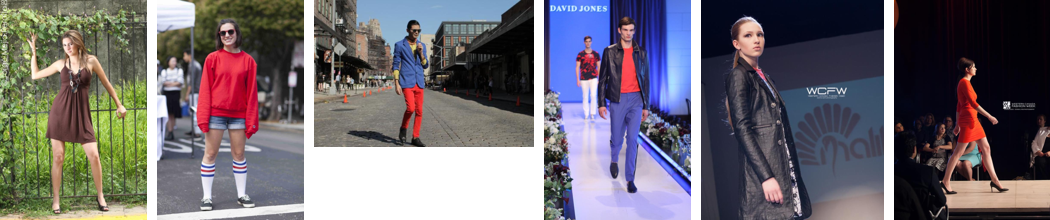

image_0001.jpg|image_0002.jpg|image_0003.jpg|image_0004.jpg|image_0005.jpg|image_0006.jpg


In [7]:
# ============================================================
# [7] 저장된 이미지 미리보기 (데이터가 어떻게 생겼는지 눈으로 확인)
# ============================================================
preview_files = image_files[:6]
if preview_files:
    preview_paths = [os.path.join(DATASET_FOLDER, name) for name in preview_files]
    show_image_grid(preview_paths, captions=preview_files)
else:
    print("미리 볼 이미지가 없습니다. [6] 셀을 먼저 실행하세요.")

> **나의 메모** : (이 칸을 더블클릭해서 수업 중 알게 된 점을 적어 보세요)
>
> - 

---
# Part 3. 임베딩 & 벡터 DB — CLIP + Chroma

### 임베딩(Embedding)이란?
데이터를 **의미를 담은 숫자 벡터**로 바꾼 것입니다. 의미가 비슷하면 벡터도 가까워집니다.

### CLIP (Contrastive Language-Image Pre-training)
- OpenAI 가 2021년에 발표한 모델 구조이며, 오늘 쓰는 것은 LAION 이 공개 데이터(LAION-2B, 약 20억 쌍)로 학습한 **OpenCLIP ViT-B-32** 입니다.
- **이미지 인코더**와 **텍스트 인코더** 두 개로 구성되며, 둘 다 **512차원** 벡터를 출력합니다.
- 학습 방법(대조 학습): "사진–설명" 짝은 벡터를 **가깝게**, 짝이 아닌 것은 **멀게** 만들도록 학습.
- 결과적으로 **텍스트와 이미지가 같은 공간**에 놓여, `"a red dress"` 텍스트 벡터 근처에 빨간 드레스 사진 벡터들이 모입니다.

```
           512차원 공간 (개념도)
   "a red dress" ●──┐
                    ├─ 가까움 →  📷 빨간 드레스 사진
                    └─ 가까움 →  📷 와인색 원피스 사진
   "a black jacket" ●────────→  📷 검정 재킷 사진   (빨간 드레스와는 멀다)
```

### 벡터 DB — Chroma
| 개념 | 설명 | 코드 |
|---|---|---|
| Client | DB 연결. `PersistentClient` 는 디스크에 저장 | `chromadb.PersistentClient(path=...)` |
| Collection | 테이블 같은 단위 | `get_or_create_collection(name=...)` |
| Embedding Function | 데이터 → 벡터 자동 변환 | `OpenCLIPEmbeddingFunction()` |
| Data Loader | URI(경로) → 실제 데이터 로딩 | `ImageLoader()` |
| add / query | 저장 / 유사도 검색 | `add(ids, uris)`, `query(query_texts, n_results)` |

**`add(uris=...)` 내부 동작**: 경로 → `ImageLoader` 가 이미지 읽기 → CLIP 이미지 인코더 → 벡터 저장
**`query(query_texts=...)` 내부 동작**: 텍스트 → CLIP 텍스트 인코더 → 저장된 이미지 벡터들과 거리 계산 → 가까운 순 반환

### 거리(distance) 읽는 법
- Chroma 기본 거리 함수는 **제곱 유클리드 거리(L2²)** 입니다. **작을수록 비슷**합니다.
- CLIP 벡터는 길이 1로 정규화되어 있어 `L2² = 2 − 2 × 코사인유사도` 관계가 성립 → 순위는 코사인 유사도와 동일합니다.


In [20]:
# ============================================================
# [8] Chroma 벡터 DB 설정 & 이미지 등록 함수
# ============================================================

def setup_chroma_db(vdb_path=VDB_PATH, collection_name=COLLECTION_NAME):
    """CLIP 임베딩 함수를 연결한 Chroma 컬렉션을 생성(또는 기존 것 로드)해 반환합니다."""
    # PersistentClient : 디스크(vdb_path)에 DB를 저장 -> 노트북을 껐다 켜도 유지
    #                    (chromadb.Client() 는 메모리 전용이라 종료 시 사라짐)
    chroma_client = chromadb.PersistentClient(path=vdb_path)

    # ImageLoader : add/query 때 넘긴 uris(파일 경로)를 실제 이미지(numpy 배열)로 읽어줌
    image_loader = ImageLoader()

    # OpenCLIPEmbeddingFunction : 기본값 ViT-B-32 모델 + laion2b_s34b_b79k 가중치
    #   - 첫 실행 시 Hugging Face 에서 약 600MB 가중치를 다운로드 (이후 캐시 사용)
    #   - 텍스트와 이미지를 '같은 512차원 공간'의 벡터로 변환 -> 텍스트로 이미지 검색 가능
    clip = OpenCLIPEmbeddingFunction()

    # get_or_create_collection : 같은 이름의 컬렉션이 있으면 가져오고, 없으면 새로 만듦
    image_vdb = chroma_client.get_or_create_collection(
        name=collection_name,
        embedding_function=clip,     # 저장/검색 시 자동으로 벡터를 계산할 함수
        data_loader=image_loader,    # uris -> 이미지 로딩 담당
    )
    return image_vdb


def add_images_to_db(image_vdb, dataset_folder=DATASET_FOLDER, batch_size=50):
    """폴더의 이미지를 벡터 DB에 등록합니다. 이미 등록된 이미지는 건너뜁니다.

    [원본 코드의 문제]
      - id 를 enumerate 번호로 부여 -> 사전식 정렬 때문에 id '1' 이 image_10.png 를 가리킴
      - DB 폴더 존재 여부로만 판단 -> 등록 도중 실패하면 빈 DB 를 계속 재사용
    [수정]
      - id = 파일명(확장자 제외)  예) 'image_0001'  -> id 와 파일이 항상 일치
      - DB에 이미 있는 id 를 조회해서 '없는 것만' 추가 (여러 번 실행해도 안전 = 멱등성)
    """
    files = list_image_files(dataset_folder)
    ids  = [os.path.splitext(f)[0] for f in files]           # 'image_0001.jpg' -> 'image_0001'
    uris = [os.path.join(dataset_folder, f) for f in files]  # 이미지 전체 경로

    # include=[] : 벡터·문서 등은 빼고 id 만 가볍게 조회
    existing_ids = set(image_vdb.get(include=[])["ids"])
    new_items = [(i, u) for i, u in zip(ids, uris) if i not in existing_ids]

    if not new_items:
        print(f"추가할 새 이미지가 없습니다. (현재 DB 이미지 수: {image_vdb.count()})")
        return

    print(f"새 이미지 {len(new_items)}장을 임베딩하여 등록합니다. (CPU 기준 수 분 소요)")
    # batch_size 장씩 나눠서 추가 -> 진행 상황 확인 + 메모리 사용량 제한
    for start in range(0, len(new_items), batch_size):
        batch = new_items[start:start + batch_size]
        image_vdb.add(
            ids=[i for i, _ in batch],    # 각 항목의 고유 ID (문자열)
            uris=[u for _, u in batch],   # 이미지 경로 -> ImageLoader 가 읽고 CLIP 이 임베딩
        )
        print(f"  ... {min(start + batch_size, len(new_items))}/{len(new_items)} 등록")
    print(f"이미지가 벡터 데이터베이스에 추가되었습니다. (총 {image_vdb.count()}장)")

print("벡터 DB 함수 정의 완료")

벡터 DB 함수 정의 완료


In [24]:
# ============================================================
# [9] 벡터 DB 생성 및 이미지 등록 실행
# ============================================================
# 컬렉션 생성 또는 로드 (CLIP 모델 로딩 포함)
image_vdb = setup_chroma_db()
add_images_to_db(image_vdb,DATASET_FOLDER)
# 아직 없는 이미지만 임베딩하여 저장

print("컬렉션 이름:", image_vdb.name, "/ 저장된 항목 수:", image_vdb.count())

추가할 새 이미지가 없습니다. (현재 DB 이미지 수: 500)
컬렉션 이름: fashion_images / 저장된 항목 수: 500


In [25]:
add_images_to_db(image_vdb,DATASET_FOLDER)

추가할 새 이미지가 없습니다. (현재 DB 이미지 수: 500)


In [26]:
# ============================================================
# [10] 텍스트로 이미지 검색 & 결과 출력 함수
# ============================================================

def query_db(image_vdb, query, results=N_RESULTS):
    """텍스트 query 와 가장 가까운 이미지를 results 개 검색합니다.

    - query_texts : 검색어 리스트 (여러 개를 한 번에 검색 가능 -> 결과도 2차원 리스트)
    - n_results   : 검색어당 반환할 결과 수
    - include     : 결과에 포함할 항목 ('ids' 는 항상 포함됨)
        'uris'      -> 이미지 파일 경로
        'distances' -> 거리(작을수록 비슷함)
    """
    return image_vdb.query(
        query_texts=[query],
        n_results=results,
        include=["uris", "distances"],
    )


def print_results(results):
    """query_db 결과를 사람이 읽기 좋게 출력하고 썸네일도 보여줍니다.

    결과 구조 예시 (검색어 1개, 결과 2개):
      {'ids':       [['image_0042', 'image_0310']],
       'uris':      [['.../image_0042.jpg', '.../image_0310.jpg']],
       'distances': [[1.52, 1.55]]}
      -> 바깥 리스트 = 검색어 순서, 안쪽 리스트 = 순위 순서  =>  [0] 으로 첫 검색어 결과 선택
    """
    uris = results["uris"][0]
    for rank, uri in enumerate(uris):
        print(f"[{rank + 1}위] ID: {results['ids'][0][rank]}")
        print(f"      Distance: {results['distances'][0][rank]:.4f}")
        print(f"      Path: {uri}")
    captions = [f"{rank + 1}위 {results['ids'][0][rank]}" for rank in range(len(uris))]
    show_image_grid(uris, captions)

print("검색 함수 정의 완료")

검색 함수 정의 완료


[1위] ID: image_0224
      Distance: 0.6934
      Path: C:\workspaces\fashion-rag\fashion_dataset\image_0224.jpg
[2위] ID: image_0107
      Distance: 0.7010
      Path: C:\workspaces\fashion-rag\fashion_dataset\image_0107.jpg
[3위] ID: image_0192
      Distance: 0.7108
      Path: C:\workspaces\fashion-rag\fashion_dataset\image_0192.jpg


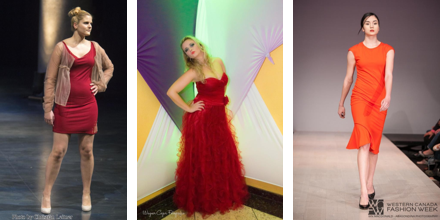

1위 image_0224|2위 image_0107|3위 image_0192


In [27]:
# ============================================================
# [11] 검색 테스트 (OpenAI 없이 CLIP + Chroma 만으로 동작)
# ============================================================
# CLIP 은 주로 영어 데이터로 학습되었으므로 검색어는 '영어'로 넣는 것이 좋습니다.
test_query = "a red dress"
results = query_db(image_vdb, test_query, results=3)
print_results(results)


**생각해 보기**: 검색어를 한국어 `"빨간 드레스"` 로 바꿔 [11] 셀을 다시 실행해 보세요. 결과가 어떻게 달라지나요? 왜 그럴까요?

> **나의 메모** : (이 칸을 더블클릭해서 수업 중 알게 된 점을 적어 보세요)
>
> - 

---
# Part 4. LangChain 체인 — 번역 체인 & 비전 체인

### LCEL (LangChain Expression Language)
`|`(파이프) 연산자로 구성요소를 이어 **체인**을 만듭니다. 앞 단계의 출력이 다음 단계의 입력이 됩니다.

```
 {"text": "...", "target_lang": "English"}   ← invoke() 에 넣는 dict
        │  ChatPromptTemplate  : 변수를 채워 메시지 목록 생성
        ▼
 [SystemMessage, HumanMessage]
        │  ChatOpenAI          : OpenAI API 호출
        ▼
 AIMessage(content="...")
        │  StrOutputParser     : content 만 꺼냄
        ▼
 "..." (str)
```

| 구성요소 | 역할 |
|---|---|
| `ChatPromptTemplate.from_messages([...])` | `("system", ...)`, `("user", ...)` 역할별 메시지 템플릿. `{변수}` 자리표시자 사용 |
| `ChatOpenAI(model, temperature)` | OpenAI 채팅 모델. `temperature` 0 = 일관된 답, 높을수록 다양한 답 |
| `StrOutputParser()` | `AIMessage` → 문자열 |
| `chain.invoke(dict)` | 체인 실행 |


In [28]:
# ============================================================
# [12] 번역 체인 (LCEL: 프롬프트 | 모델 | 파서)
# ============================================================
# 원본은 translate() 를 호출할 때마다 모델·프롬프트·체인을 새로 만들었습니다.
# -> 체인을 '한 번만' 만들고, 목표 언어(target_lang)도 프롬프트 변수로 받아 재사용합니다.

# temperature=0.0 : 무작위성 최소화 -> 번역처럼 '정답에 가까운 출력'이 필요할 때 사용
translation_model = ChatOpenAI(model=TRANSLATION_MODEL , temperature=0.0)

# ChatPromptTemplate.from_messages : (역할, 내용) 튜플 리스트로 대화형 프롬프트 생성
#   {target_lang}, {text} 는 invoke 할 때 채워지는 '자리표시자(변수)'
translation_prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a professional translator. "
               "Translate the following text to {target_lang}. "
               "Keep markdown formatting. Output only the translation."),
    ("user", "{text}"),
])



# | (파이프) 연산자로 구성요소를 연결 = LCEL(LangChain Expression Language)
#   입력 dict -> 프롬프트(메시지 목록) -> 모델(AIMessage) -> 파서(str)
translation_chain = translation_prompt | translation_model | StrOutputParser()

def translate(text, target_lang):
    return translation_chain.invoke({"text": text , "target_lang":target_lang})


# def translate(text, target_lang):
#     """text 를 target_lang(예: 'English', 'Korean')으로 번역한 문자열을 반환합니다."""



# 동작 확인
print(translate("데이트할 때 입을 빨간 원피스", "English"))

A red dress to wear on a date.


### 비전 모델에 이미지를 보내는 방법

비전 모델(gpt-4o, gpt-4o-mini)은 user 메시지에 **콘텐츠 블록 리스트**를 받습니다.
```python
[
  {"type": "text",      "text": "질문 ..."},
  {"type": "image_url", "image_url": {"url": "https://... 또는 data:image/jpeg;base64,...."}},
]
```

### base64 와 data URL
- 이미지 파일은 **바이너리(0과 1)** 라서 JSON 텍스트에 바로 넣을 수 없습니다.
- **base64** 는 바이너리를 `A-Z a-z 0-9 + /` 64개 문자로 표현하는 인코딩입니다 (용량은 약 1.33배로 늘어남).
- **data URL** = `data:<MIME 타입>;base64,<base64 문자열>` → 파일을 인터넷에 올리지 않고 URL 자리에 직접 넣을 수 있습니다.
- MIME 타입은 실제 파일 형식과 맞춰야 합니다 (`.jpg` → `image/jpeg`, `.png` → `image/png`).

```
 image_0123.jpg (bytes) ─b64encode─▶ b'/9j/4AAQSk...' ─decode─▶ '/9j/4AAQSk...' (str)
                                                              ─▶ 'data:image/jpeg;base64,/9j/4AAQSk...'
```


In [30]:
# ============================================================
# [13] 비전(멀티모달) 체인: 텍스트 + 이미지 2장을 함께 LLM 에 전달
# ============================================================

def setup_vision_chain():
    """패션 스타일링 조언을 생성하는 '프롬프트 | 비전모델 | 파서' 체인을 반환합니다."""
    # gpt-4o / gpt-4o-mini 는 이미지를 입력으로 이해하는 멀티모달 모델
    vision_model = ChatOpenAI(model=VISION_MODEL, temperature=0.0)
    parser = StrOutputParser()

    # system: 모델의 역할·말투 지정
    #  (해석) 당신은 유용한 패션 및 스타일링 보조자입니다. 제공된 이미지의 특정 부분을 직접 언급하며
    #         이미지 컨텍스트를 사용해 질문에 답하세요. 대화하듯 답하고 목록은 너무 많이 쓰지 마세요.
    #         강조와 구조화를 위해 마크다운을 사용하세요.
    #
    # user: '콘텐츠 블록 리스트' 형식 -> 텍스트 블록 1개 + 이미지 블록 2개
    #   이미지 블록의 url 에 data URL(= data:<MIME>;base64,<데이터>)을 넣으면
    #   이미지 파일을 인터넷에 올리지 않고도 모델에 직접 전달할 수 있음
    #   [원본 수정] PNG 파일인데 'image/jpeg' 로 고정 -> 실제 파일 형식(MIME)을 변수로 전달
    image_prompt = ChatPromptTemplate.from_messages([
        ("system",
         "You are a helpful fashion and styling assistant. "
         "Answer the user's question using the given image context with direct references "
         "to parts of the images provided. Maintain a more conversational tone, "
         "don't make too many lists. Use markdown formatting for highlights, emphasis, and structure."),
        ("user", [
            {"type": "text", "text": "What are some ideas for styling {user_query}"},
            {"type": "image_url", "image_url": {"url": "data:{image_mime_1};base64,{image_data_1}"}},
            {"type": "image_url", "image_url": {"url": "data:{image_mime_2};base64,{image_data_2}"}},
        ]),
    ])
    # 프롬프트 -> 모델 -> 문자열 파서 를 하나의 체인으로 연결해 반환
    return image_prompt | vision_model | parser


def encode_image(path):
    """이미지 파일을 읽어 base64 문자열로 변환합니다.
    바이너리(bytes) --b64encode--> base64 bytes --decode('utf-8')--> 일반 문자열(str)"""
    # 'rb' = 바이너리 읽기 모드
    with open(path,"rb") as f:
        return base64.b64encode(f.read()).decode("utf-8")


def format_prompt_inputs(data, user_query):
    """검색 결과(data)와 질문으로 비전 프롬프트에 넣을 입력 dict 를 만듭니다.

    반환 예시: {'user_query': '...', 'image_data_1': '/9j/4AAQ...', 'image_mime_1': 'image/jpeg', ...}
    """
    uris =  data["uris"][0]             # 첫 번째 검색어의 결과 경로 목록

    # 원본 코드는 결과가 2개 미만이면 IndexError 로 중단됨 -> 이해하기 쉬운 메시지로 안내
    if len(uris)<2:
        raise ValueError(f"이미지가 최소 2장이 필요합니다. 검색결과 {len(uris)}장")

    inputs = {"user_query": user_query}

    # 상위 2장만 사용 (n = 1, 2)
    for n, path in enumerate(uris[:2], start=1):
        inputs[f"image_data_{n}" ] = encode_image(path)
        inputs[f"image_mime_{n}"] = guess_mime(path)
    return inputs

vision_chain = setup_vision_chain()
print("비전 체인 준비 완료")

비전 체인 준비 완료


> **나의 메모** : (이 칸을 더블클릭해서 수업 중 알게 된 점을 적어 보세요)
>
> - 

---
# Part 5. 전체 파이프라인 조립

지금까지 만든 부품을 RAG 순서대로 연결합니다.

| 단계 | 함수 | RAG 역할 |
|---|---|---|
| ① 질문 번역 | `translate(query_ko, "English")` | 전처리 |
| ② 이미지 검색 | `query_db(image_vdb, query_en)` | **R**etrieval |
| ③ 프롬프트 입력 구성 | `format_prompt_inputs(results, query_en)` | **A**ugmentation |
| ④ 답변 생성 | `vision_chain.invoke(prompt_input)` | **G**eneration |
| ⑤ 답변 번역 | `translate(response_en, "Korean")` | 후처리 |


In [31]:
# ============================================================
# [14] 전체 파이프라인: 한국어 질문 -> 번역 -> 검색 -> 비전 LLM -> 번역 -> 출력
# ============================================================

def ask_fashion_rag(query_ko, n_results=N_RESULTS, show=True):
    """한국어 질문 하나를 받아 FashionRAG 전체 과정을 실행하고 결과 dict 를 반환합니다."""
    # ① 한국어 질문 -> 영어 (CLIP 검색 품질과 LLM 이해도를 높이기 위해)
    query_en = translate(query_ko,"English")

    # ② CLIP 임베딩 기반 이미지 검색 (Retrieval)
    results = query_db(image_vdb , query_en , results=n_results)

    # ③ 검색된 이미지 + 질문을 프롬프트 입력으로 변환 (Augmentation)
    prompt_input = format_prompt_inputs(results, query_en)

    # ④ 비전 모델이 이미지를 보고 스타일링 조언 생성 (Generation)
    response_en = vision_chain.invoke(prompt_input)

    # ⑤ 영어 답변 -> 한국어
    response_ko = translate(response_en, "Korean")

    if show:
        print("번역된 검색어:", query_en)
        print("\n[검색된 이미지]")
        print_results(results)
        print("\n[FashionRAG 의 응답]")
        display(Markdown(response_ko))   # 마크다운(굵게, 제목 등)을 렌더링해서 출력

    return {"query_en": query_en, "results": results,
            "response_en": response_en, "response_ko": response_ko}

번역된 검색어: Please tell me about dress styling suitable for wedding guest outfits.

[검색된 이미지]
[1위] ID: image_0231
      Distance: 0.7300
      Path: C:\workspaces\fashion-rag\fashion_dataset\image_0231.jpg
[2위] ID: image_0380
      Distance: 0.7438
      Path: C:\workspaces\fashion-rag\fashion_dataset\image_0380.jpg


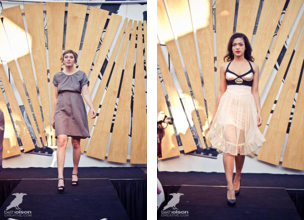

1위 image_0231|2위 image_0380

[FashionRAG 의 응답]


결혼식 하객 의상 스타일링은 재미있고 우아할 수 있습니다! 제공하신 이미지의 두 드레스를 살펴보고 몇 가지 스타일링 아이디어를 탐색해 보겠습니다.

### 드레스 1: 회색 드레스
이 드레스는 간단하고 세련된 실루엣으로, 격식 있게 또는 캐주얼하게 입을 수 있습니다. 다음은 몇 가지 스타일링 팁입니다:

- **액세서리**: 대담한 귀걸이나 두꺼운 팔찌와 같은 포인트 주얼리와 매치하여 화려함을 더하세요. 더 절제된 룩을 원하신다면 섬세한 목걸이도 잘 어울립니다.
  
- **신발**: 메탈릭 색상의 스트랩 힐이나 우아한 펌프스를 선택하여 의상을 한층 높여보세요. 검정색이나 누드 색상도 회색과 잘 어울립니다.

- **아우터웨어**: 결혼식이 더 쌀쌀한 계절에 열리는 경우, 따뜻하게 유지하면서도 세련된 느낌을 주는 맞춤형 블레이저나 스타일리시한 숄을 고려해 보세요.

- **가방**: 딥 버건디나 네이비와 같은 대조적인 색상의 클러치가 색감을 더하고 필수품을 손쉽게 보관할 수 있습니다.

### 드레스 2: 시스루 스커트 드레스
이 드레스는 더 대담하고 장난기 있는 분위기를 가지고 있습니다. 스타일링 방법은 다음과 같습니다:

- **레이어링**: 드레스가 시스루 스커트이므로, 스타일리시한 레이어드 룩을 위해 몸에 꼭 맞는 바디수트나 세련된 브라렛을 아래에 입는 것을 고려해 보세요.

- **신발**: 엣지를 더하기 위해 하이힐 샌들이나 앵클 부츠를 선택하세요. 빨강이나 로열 블루와 같은 대담한 색상이 강렬한 포인트가 될 수 있습니다.

- **액세서리**: 드레스가 돋보일 수 있도록 미니멀한 주얼리를 선택하세요. 스터드 귀걸이나 간단한 팔찌가 잘 어울립니다.

- **아우터웨어**: 가죽 재킷이 예상치 못한 변화를 줄 수 있어 의상을 더 현대적이고 엣지 있게 만들어 줍니다.

- **가방**: 보완 색상의 작은 크로스바디 백이나 클러치가 룩을 조화롭게 묶어주면서 과하지 않게 연출할 수 있습니다.

### 일반 팁
- **색상 팔레트**: 의상과 액세서리를 선택할 때 결혼식의 색상 조합을 고려하세요.
- **편안함**: 특히 춤을 출 예정이라면 의상에서 편안하게 움직일 수 있는지 확인하세요!
- **드레스 코드**: 항상 초대장에서 특정 드레스 코드 지침을 확인하세요.

이 아이디어들을 통해 개인 스타일을 반영하면서도 행사에 적합한 멋진 결혼식 하객 룩을 연출할 수 있습니다!

In [32]:
# ============================================================
# [15] FashionRAG 실행해 보기
# ============================================================
answer = ask_fashion_rag("결혼식 하객룩으로 어울리는 원피스 스타일링 알려줘")

다른 질문으로도 바꿔 실행해 보세요. 예) `"하객룩으로 어울리는 원피스"`, `"캐주얼한 데님 재킷 코디"`, `"여름 휴가지에서 입을 린넨 셔츠"`

In [ ]:
# ============================================================
# [16] (선택) 대화형 모드 - 원본 스크립트의 while 루프
# ============================================================
# 노트북에서 input() 무한 루프를 바로 돌리면 '셀 전체 실행' 시 멈춘 것처럼 보이므로
# 기본값은 False 입니다. 직접 대화해 보고 싶을 때만 True 로 바꿔 실행하세요.
RUN_INTERACTIVE = False

if RUN_INTERACTIVE:
    print("FashionRAG 가 여러분의 서비스를 위해 준비되었습니다!")
    while True:
        query_ko = input("\n스타일 질문을 입력하세요 (종료: quit): ").strip()
        if query_ko.lower() in ("quit", "exit", "q", "종료"):
            print("FashionRAG 를 종료합니다.")
            break
        if not query_ko:          # 빈 입력은 무시
            continue
        try:
            ask_fashion_rag(query_ko)
        except Exception as e:    # API 오류 등이 나도 루프가 죽지 않도록 처리
            print("오류가 발생했습니다:", e)
else:
    print("대화형 모드를 사용하려면 RUN_INTERACTIVE = True 로 바꾸고 다시 실행하세요.")

> **나의 메모** : (이 칸을 더블클릭해서 수업 중 알게 된 점을 적어 보세요)
>
> - 

---
# Part 6. ✏️ 실습 문제



### 실습 1. 검색 개수 바꾸기
`"a black leather jacket"` 과 가장 비슷한 사진 **4장**을 찾아 출력하세요.


In [ ]:
# [실습 1] "a black leather jacket" 과 비슷한 이미지 4장을 검색하고 출력해 보세요.
# 힌트: query_db(컬렉션, 검색어, results=개수) / print_results(결과)


### 실습 2. 이미지로 이미지 검색 (Image → Image)
CLIP 은 이미지와 텍스트가 같은 공간에 있으므로, **사진을 검색어로** 넣어 비슷한 사진을 찾을 수도 있습니다. `query_uris` 를 사용해 보세요.

In [ ]:
# [실습 2] 이미지로 이미지 검색하기 (Image -> Image)
# CLIP 은 이미지와 텍스트가 같은 벡터 공간에 있으므로 '이미지'로도 검색할 수 있습니다.
# Chroma 의 query() 는 query_texts 대신 query_uris(이미지 경로 리스트)를 받을 수 있습니다.
# 첫 번째 이미지를 검색어로 사용


# TODO: 이미지 경로 '리스트'를 넣으세요



print_results(ex2_results)
# 질문: 1위 결과는 무엇이고, distance 는 얼마인가요? 왜 그럴까요?

### 실습 3. 페르소나 바꾸기
system 프롬프트만 바꿔서 **'가성비 스타일리스트'** 챗봇을 만들어 보세요.

In [ ]:
# [실습 3] 페르소나 바꾸기: '예산 친화적(가성비) 스타일리스트' 체인 만들기
# 아래 system 메시지를 '저렴한 아이템으로 비슷한 느낌을 내는 방법을 알려주는 스타일리스트'로 바꿔 보세요.
budget_prompt = ChatPromptTemplate.from_messages([
    ("system", "TODO: 여기에 영어로 새로운 역할을 작성하세요"),
    ("user", [
        {"type": "text", "text": "What are some ideas for styling {user_query}"},
        {"type": "image_url", "image_url": {"url": "data:{image_mime_1};base64,{image_data_1}"}},
        {"type": "image_url", "image_url": {"url": "data:{image_mime_2};base64,{image_data_2}"}},
    ]),
])
budget_chain = None   # TODO: budget_prompt | 모델 | 파서 로 체인을 완성하세요

q = translate("출근룩으로 입을 니트", "English")
inputs = format_prompt_inputs(query_db(image_vdb, q), q)
display(Markdown(translate(budget_chain.invoke(inputs), "Korean")))

### 실습 4. 거리 임계값 필터
너무 동떨어진 사진은 LLM 에 보내지 않는 것이 좋습니다. distance 가 기준 이하인 결과만 남기는 함수를 완성하세요.

In [ ]:
# [실습 4] 거리 임계값(threshold) 필터
# 검색 결과 중 distance 가 기준값 '이하'(=충분히 비슷한)인 결과만 남기는 함수를 완성하세요.
def filter_by_distance(results, max_distance):
    kept = []
    for rid, uri, dist in zip(results["ids"][0], results["uris"][0], results["distances"][0]):
        if None:            # TODO: 조건을 작성하세요
            kept.append((rid, uri, dist))
    return kept

r = query_db(image_vdb, "a person wearing sunglasses", results=5)
print("전체 거리:", [round(d, 3) for d in r["distances"][0]])
print("필터 결과:", filter_by_distance(r, max_distance=1.5))

---
# 확인 퀴즈

1. CLIP 으로 **텍스트로 이미지를 검색**할 수 있는 이유는 무엇인가요?
2. Chroma 에서 `distance` 값이 **작을수록** 의미하는 것은?
3. 이미지를 OpenAI 비전 모델에 보낼 때 **base64 로 인코딩**하는 이유는?
4. `load_dataset(..., streaming=True)` 를 쓰면 무엇이 좋아지나요?
5. 원본 스크립트를 노트북으로 옮겼을 때 `__file__` 에서 에러가 나는 이유는?
6. FashionRAG 에서 번역을 두 번(질문, 답변) 하는 이유는?
7. LCEL 에서 `prompt | model | parser` 각 단계의 **출력 타입**을 순서대로 적어 보세요.

(답을 아래 메모 칸에 적어 보세요)


> **나의 메모** : (이 칸을 더블클릭해서 수업 중 알게 된 점을 적어 보세요)
>
> - 

---
# 정리

| 오늘 배운 것 | 핵심 한 줄 |
|---|---|
| 멀티모달 RAG | 이미지를 검색해서 비전 LLM 의 근거로 사용 |
| CLIP | 텍스트와 이미지를 같은 벡터 공간에 → 텍스트로 이미지 검색 |
| Chroma | `embedding_function` + `data_loader` 로 경로만 넣으면 임베딩·저장 자동 |
| LCEL | `prompt | model | parser`, `invoke(dict)` |
| 비전 입력 | `{"type": "image_url", "image_url": {"url": "data:<MIME>;base64,..."}}` |

### 더 나아가기
- **다국어 CLIP**(예: `xlm-roberta-base-ViT-B-32`)을 쓰면 번역 없이 한국어로 바로 검색 가능
- **메타데이터 필터**: Fashionpedia 의 의류 카테고리를 `metadatas` 로 저장해 `where={"category": "dress"}` 로 필터 검색
- **대화 기억**: `RunnableWithMessageHistory` 로 이전 질문 맥락 유지
- **웹 UI**: Gradio / Streamlit 으로 `ask_fashion_rag()` 를 감싸 웹 데모 만들기
